# Does reasoning help? Baseline AutoResearch with and without a reasoning step
*Agentic AI Systems · Harness Design II · symbolic regression on LLM-SRBench*

Baseline AutoResearch (H1) is a single agent that repeats **reason → act → observe**. We compare two versions
that differ in one design choice only:

| Harness | One round |
|---|---|
| `baseline_autoresearch` | 1. **reason**: reason about the next tool call (no tools offered) · 2. **act**: make the tool call |
| `baseline_autoresearch_no_reasoning` | **act**: make the tool call directly |

In both, the harness appends a record of each round (`Round t / [Reasoning] / Tool call / Result`) to the history,
so later rounds see everything earlier rounds did. Same model, tasks, seeds, evaluator and budget.

**Budget:** 5 equation evaluations per run, so the history stays short in both cases.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sr_harness import load_config
from sr_harness.analysis import plots
from sr_harness.analysis.paired import paired_table
from sr_harness.benchmark import load_tasks
from sr_harness.experiments.runner import run_grid
from sr_harness.llm import LLMClient

LIVE = False        # False: replay the recorded runs; True: run the experiment (OpenRouter + HF login)
ROOT = "runs" if LIVE else "recorded"
OUT = f"{ROOT}/reasoning_ablation"
A, B = "baseline_autoresearch_no_reasoning", "baseline_autoresearch"
N_TASKS, SEEDS, BUDGET = 129, [0, 1, 2, 3], 5

cfg = load_config()
cfg["benchmark"]["n_tasks"] = N_TASKS
cfg["experiment"]["budget"]["max_evaluations"] = BUDGET
print("model:", cfg["model"]["model"], "| reasoning effort:", cfg["model"]["reasoning_effort"])

model: openai/gpt-oss-20b | reasoning effort: low


## 1. The two rounds
What the model is asked in each step of round *t*:

In [2]:
from sr_harness.prompts import baseline_autoresearch as P

print("WITH REASONING\n  step 1 (reason):", P.reason_message(3).replace("\n", " "))
print("  step 2 (act):   ", P.ACTION_PROMPT)
print("\nWITHOUT REASONING\n  only step (act):", P.round_message(3))

WITH REASONING
  step 1 (reason): Round 3. First, give your reasoning for the next tool call: what do the earlier rounds show, which tool will you call (evaluate_equation with which equation, or finish), and why? Answer in 1-3 sentences. Do not call a tool yet.
  step 2 (act):    Now make the tool call your reasoning describes.

WITHOUT REASONING
  only step (act): Round 3. Make your next tool call.


## 2. Run the experiment (or load the recorded runs)
All 129 LSR-Synth tasks of LLM-SRBench × 4 seeds × 2 harnesses = 1032 runs. Finished runs are skipped, so an
interrupted run can be resumed.

In [3]:
if LIVE:
    tasks = load_tasks(cfg["benchmark"])
    make_llm = lambda logger, seed: LLMClient(cfg["model"], logger=logger, seed=seed)
    run_grid(tasks, [A, B], SEEDS, cfg, make_llm, OUT)

results = [r for r in plots.load_results(OUT) if r["harness"] in (A, B)]
print(len(results), "runs:", pd.Series([r["harness"] for r in results]).value_counts().to_dict())

1032 runs: {'baseline_autoresearch': 516, 'baseline_autoresearch_no_reasoning': 516}


## 3. Performance vs. time step
At each time step *k* the run's answer is its best equation so far **by train R²** (the score the agent optimizes);
we score that equation on the training data and on two hidden splits:

| Data | Question |
|---|---|
| **train**: the data the agent searches on | what the harness optimizes |
| **ID** (in distribution): new points from the training range | does the equation interpolate? |
| **OOD** (out of distribution): points beyond the training range (about 11% further, mostly in time) | did the search find the law, or only a curve? |

Two scores: **R²** = 1 − MSE / variance of the target *within that split*, and the **MSE** itself, in the target's
units, so train and OOD of one task are directly comparable. Across tasks we average MSE in log space (a geometric
mean): target scales differ by up to 16 orders of magnitude (variance 10⁻⁷ to 10⁹), so an arithmetic mean would be
the MSE of the largest-scale task. Before its first valid equation (or if it never has one) a run gets the MSE of
predicting the training mean.

Mean over tasks (seeds averaged per task); bars: 95% bootstrap interval over tasks.

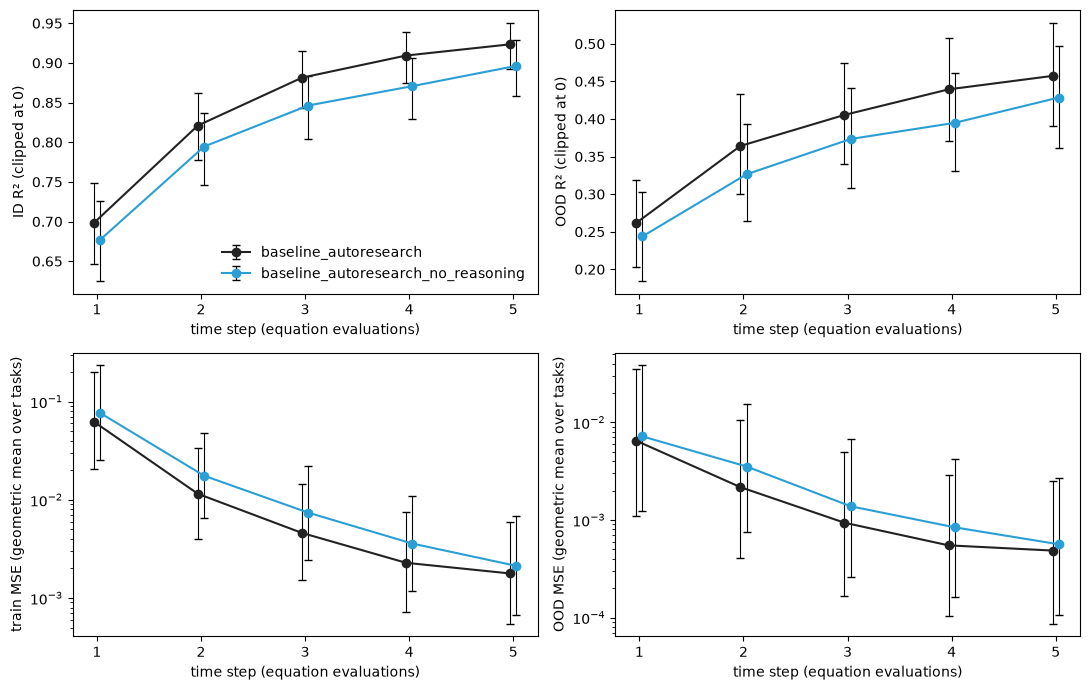

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, metric in zip(axes.flat, ["train_dist_r2", "ood_r2", "train_mse", "ood_mse"]):
    plots.plot_vs_steps(results, metric, max_step=BUDGET, ax=ax)
for ax in list(axes.flat)[1:]:
    ax.get_legend().remove()
fig.tight_layout()
plt.show()

**Paired comparison after 5 steps.** The intervals above are per harness. Comparing the two harnesses *on the same
task* (seeds averaged per task; 95% CI = mean ± 1.96·sd/√n, as in Harness Design I) is more sensitive:

In [5]:
table, n = paired_table(results, A, B)
rows = ["ID R² (clipped at 0)", "OOD R² (clipped at 0)", "log10 OOD MSE", "tokens"]
print(f"B − A, with B = {B}, A = {A}; n = {n} tasks")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(table.loc[rows, ["diff (B - A)", "95% CI", "median diff", "tasks B higher / lower / tie"]])

B − A, with B = baseline_autoresearch, A = baseline_autoresearch_no_reasoning; n = 129 tasks


,diff (B - A),95% CI,median diff,tasks B higher / lower / tie
metric,,,,
ID R² (clipped at 0),0.0271,"[+0.00952, +0.0447]",0.00138,78 / 47 / 4
OOD R² (clipped at 0),0.0288,"[-0.00914, +0.0667]",0,53 / 43 / 33
log10 OOD MSE,-0.0641,"[-0.294, +0.166]",-0.00866,58 / 71 / 0
tokens,6.91e+03,"[+6.45e+03, +7.37e+03]",7.85e+03,127 / 2 / 0


**Two checks.** How many tasks the first guess already fits (ID R² ≥ 0.99 at step 1),
and how often R² is negative (clipped to 0 in the plots) at step 5.

In [6]:
rows = []
for h in (A, B):
    s1 = plots.step_table([r for r in results if r["harness"] == h], "train_dist_r2", BUDGET)
    first = s1[s1.step == 1].groupby("task")["value"].mean()
    last = s1[s1.step == BUDGET].groupby("task")["value"].mean()
    neg = [r for r in results if r["harness"] == h]
    rows.append({"harness": h,
                 "tasks with ID R² ≥ 0.99, step 1": f"{(first >= 0.99).mean():.0%}",
                 f"tasks with ID R² ≥ 0.99, step {BUDGET}": f"{(last >= 0.99).mean():.0%}",
                 "runs with negative ID R²": sum(1 for r in neg if r["scores"]["train_dist"] and r["scores"]["train_dist"]["r2"] < 0),
                 "runs with negative OOD R²": sum(1 for r in neg if r["scores"]["ood"] and r["scores"]["ood"]["r2"] < 0),
                 "runs": len(neg)})
pd.DataFrame(rows).set_index("harness")

,"tasks with ID R² ≥ 0.99, step 1","tasks with ID R² ≥ 0.99, step 5",runs with negative ID R²,runs with negative OOD R²,runs
harness,,,,,
baseline_autoresearch_no_reasoning,5%,45%,9,260,516
baseline_autoresearch,9%,56%,3,243,516


### What reasoning costs
Cumulative inference tokens (all calls) after each time step. With reasoning, every round makes two model calls.

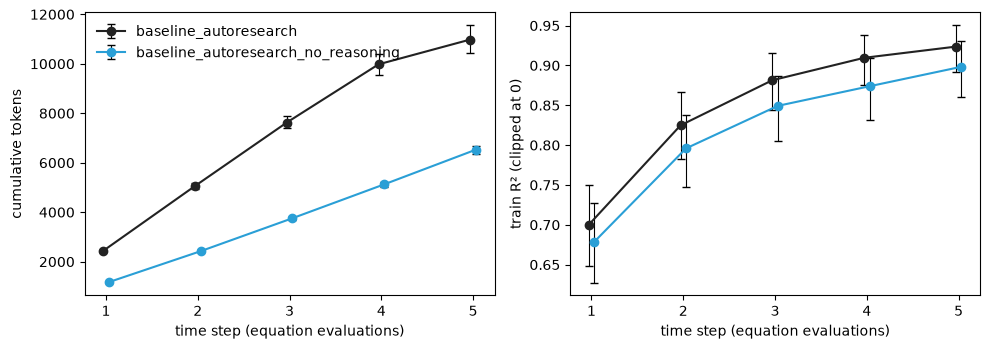

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
plots.plot_vs_steps(results, "tokens", max_step=BUDGET, ax=axes[0])
plots.plot_vs_steps(results, "train_r2", max_step=BUDGET, ax=axes[1])
axes[1].get_legend().remove()
fig.tight_layout()
plt.show()

## 3b. Performance vs. tokens
The same runs, but the x-axis is the compute spent: cumulative tokens of all model calls (bands: 95% bootstrap
interval over tasks). At a matched token budget the comparison can reverse. The dotted line marks where the runs
without reasoning end on average: their 5 evaluations are used up, so their curve is flat from there because they
**stopped**, not because they plateaued; with more evaluations they could keep improving.

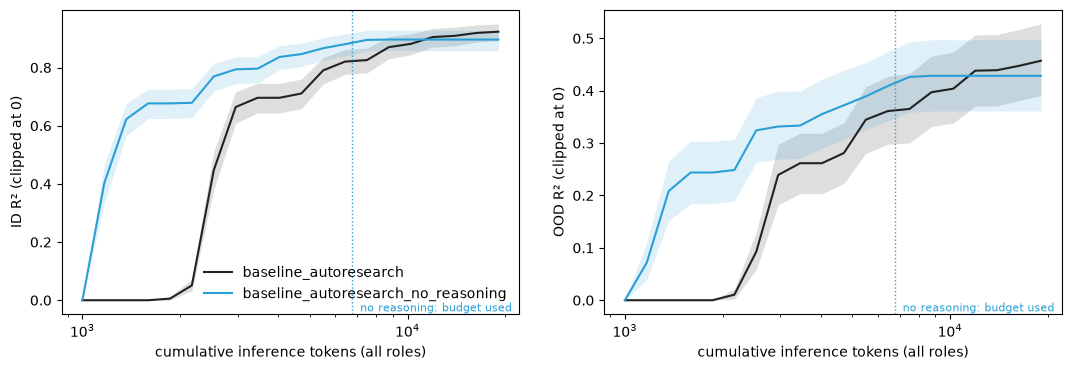

In [8]:
end_a = np.mean([r["input_tokens"] + r["output_tokens"] for r in results if r["harness"] == A])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric in zip(axes, ["train_dist_r2", "ood_r2"]):
    plots.plot_vs_tokens(results, metric=metric, ax=ax)
    ax.axvline(end_a, color=plots.COLORS[A], ls=":", lw=1)
    ax.text(end_a, ax.get_ylim()[0], "  no reasoning: budget used", color=plots.COLORS[A], fontsize=8, va="bottom")
axes[1].get_legend().remove()
fig.tight_layout()
plt.show()

## 4. Traces: one task, both harnesses
Two tasks chosen by construction, so they are not typical (most tasks come out about the same; see the paired
table): among tasks where both runs evaluated at least 3 equations (seed 0), the one where reasoning helps most in
ID R², and the one where it hurts most.

**The full prompt.** First, exactly what the agent with reasoning receives in round 1 (from the run log): the system
prompt (task, data, tool rules, role) and the round-1 message. The agent without reasoning gets the same task block,
its own role text, and the message "Round 1. Make your next tool call." 

In [9]:
def run(h, task, seed=0):
    return next(r for r in results if r["harness"] == h and r["task_id"] == task and r["seed"] == seed)

def r2(r, split):
    return max(0.0, r["scores"][split]["r2"]) if r["scores"][split] else 0.0

# runs that never evaluated an equation (e.g. the model returned empty replies) have nothing to trace
empty = [r["run_id"] for r in results if r["evaluations"] == 0]
print(f"runs without any evaluation: {len(empty)} of {len(results)}", empty)

# trace a task where both runs evaluated at least 3 equations and their scores differ most
done = {(r["harness"], r["task_id"]) for r in results if r["seed"] == 0 and r["evaluations"] >= 3}
tasks_both = sorted(t for h, t in done if h == A and (B, t) in done)
gain = {t: r2(run(B, t), "train_dist") - r2(run(A, t), "train_dist") for t in tasks_both}
task = max(gain, key=gain.get)                       # reasoning helps most
task_loss = min(gain, key=gain.get)                  # reasoning hurts most

from sr_harness.harnesses.baseline_autoresearch import clean_reasoning

def show_trajectory(h, task, seed=0):
    r = run(h, task, seed)
    log = Path(OUT, "logs", f"{h}__{task.replace('/', '-')}__s{seed}.jsonl")
    print(f"--- {h}   (ID R² = {r2(r, 'train_dist'):.4f}, OOD R² = {r2(r, 'ood'):.4f})")
    for e in map(json.loads, open(log)):
        if e["event"] == "evaluation":
            score = f"train R² = {e['train_r2']:.4f}" if e["error"] is None else f"error: {e['error'][:60]}"
            if e.get("reasoning"):
                print(f"  reasoning: {clean_reasoning(e['reasoning'])[:300]}")
            print(f"  [{e['index']}] {e['expression']}   ->  {score}")

def first_prompt(h, task, seed=0):
    log = Path(OUT, "logs", f"{h}__{task.replace('/', '-')}__s{seed}.jsonl")
    return next(e["request"] for e in map(json.loads, open(log)) if e["event"] == "model_call")

print("task:", task, "\n")
for m in first_prompt(B, task):
    print(f"===== {m['role'].upper()} =====")
    print(m["content"], "\n")

runs without any evaluation: 1 of 1032 ['baseline_autoresearch__chem_react-CRK34__s0']
task: phys_osc/PO3 

===== SYSTEM =====
# Symbolic regression task
Domain: a nonlinear oscillator in physics.
Discover an equation for dv_dt (Acceleration in Nonl-linear Harmonic Oscillator) as a function of t (Time), v (Velocity at time t).

Target: dv_dt (Acceleration in Nonl-linear Harmonic Oscillator)
Input variables:
  t: Time
  v: Velocity at time t

Training observations (30 of 4000 rows; the evaluator uses all of them):
          t            v        dv_dt
  (data rows not included in the recorded runs: LLM-SRBench is gated; run live to see them)

# The evaluate_equation tool
Write an expression for dv_dt in Python syntax using the input variables, numbers,
free constants c0, c1, ... (fitted to the training data by least squares, at most 8),
+ - * / **, and the functions sin, cos, tan, arcsin, arccos, arctan, sinh, cosh, tanh, exp, log, sqrt, abs, and the constants pi and e.
Example: c0*t**2

**The traces.** Each line is one round: the reasoning (if any), the equation evaluated and its train R².
First the task where reasoning helps most:

In [10]:
print("task:", task, f"(reasoning − none, ID R²: {gain[task]:+.3f})\n")
show_trajectory(A, task)
print()
show_trajectory(B, task)

task: phys_osc/PO3 (reasoning − none, ID R²: +0.994)

--- baseline_autoresearch_no_reasoning   (ID R² = 0.0062, OOD R² = 0.0000)
  [1] c0*v   ->  train R² = -0.0006
  [2] c0*v + c1*t   ->  train R² = 0.0019
  [3] c0*v + c1*v**2   ->  train R² = -0.0005
  [4] c0*v + c1*v**3   ->  train R² = 0.0001
  [5] c0*sin(v)   ->  train R² = -0.0006

--- baseline_autoresearch   (ID R² = 1.0000, OOD R² = 1.0000)
  reasoning: I’ll start by testing a simple linear model in the two variables:  
`dv_dt = c0 + c1*v + c2*t`.  
This uses only three free constants, is easy to fit, and will give an idea of how much of the variance is captured by linear dependencies before moving on to more complex terms.
  [1] c0 + c1*v + c2*t   ->  train R² = 0.0028
  reasoning: The linear model explains almost none of the variance, suggesting a strong nonlinear dependence on velocity. A common form for a nonlinear oscillator is a cubic term, so I’ll test `dv_dt = c0*v + c1*v**3`. This uses two free constants, remains simpl

Then the task where reasoning hurts most:

In [11]:
print("task:", task_loss, f"(reasoning − none, ID R²: {gain[task_loss]:+.3f})\n")
show_trajectory(A, task_loss)
print()
show_trajectory(B, task_loss)

task: chem_react/CRK32 (reasoning − none, ID R²: -0.801)

--- baseline_autoresearch_no_reasoning   (ID R² = 0.9451, OOD R² = 0.0000)
  [1] c0*A + c1   ->  train R² = 0.0173
  [2] c0*(c1 - A)   ->  train R² = 0.0173
  [3] c0*A**c1   ->  train R² = 0.0189
  [4] c0/t + c1*A   ->  error: non-finite predictions on 1 of 4000 training points (overflo
  [5] c0 + c1*exp(-c2*t)   ->  train R² = 0.9496

--- baseline_autoresearch   (ID R² = 0.1436, OOD R² = 0.0000)
  reasoning: I will try a simple linear model with both \(t\) and \(A\) as independent variables:  
`c0*t + c1*A + c2`. This form can capture a baseline rate, a time‑dependent trend, and a concentration dependence, which are common in kinetic equations. This is the next tool call.
  [1] c0*t + c1*A + c2   ->  train R² = 0.1550
  reasoning: The linear model performed poorly, indicating that the rate depends non‑linearly on concentration. In first‑order decay kinetics the rate is typically proportional to the remaining concentration (or i